In [ ]:
import pandas as pd
import os
from pydub import AudioSegment
from pydub.playback import play

def get_time(row):
    """
    this function returns the start and end time for the interval in milliseconds

    Parameters
    ----------
    row : pandas Series
        a row of the dataframe containing the filename, start_datetime and end_datetime
    Returns
    -------
    Start : int
        the start time of the interval in seconds
    End : int
        the end time of the interval in seconds
    """

    initial_time = row["filename"][11:-4]
    initial_time = int(initial_time[:2])*3600 + int(initial_time[3:5])*60 + int(initial_time[6:8])
    initial_time = initial_time * 1000

    Start = row['start_datetime'][11:26]
    End = row['end_datetime'][11:26]
    Start=int(float(Start[:2]))*3600 + int(float(Start[3:5]))*60 + int(float(Start[6:8])) + float("0." + Start[9:])
    End=int(float(End[:2]))*3600 + int(float(End[3:5]))*60 + int(float(End[6:8])) + float("0." + End[9:])

    Start *= 1000
    End *= 1000

    Start = Start - initial_time
    End = End - initial_time

    return Start, End


os.makedirs('waves', exist_ok=False)

for file in os.scandir('biodcase_development_set/train/annotations'):
    if file.is_file() and file.name.endswith('.csv'):
        df = pd.read_csv(file.path)
        
        for index, row in df.iterrows():
            wave_name=row['filename']
            folder_name = row['dataset']
            wav_file = AudioSegment.from_file(file='biodcase_development_set/train/audio/' +folder_name+ '/' +wave_name, format="wav")
           
            Start, End = get_time(row)
            print(Start, End)
            newAudio=wav_file[Start:End]

            newfilename = row["annotation"] + '_' + str(row["low_frequency"]) + '_' + str(row["high_frequency"]) + ".wav"
            newAudio.export('waves/' + newfilename, format="wav")

maudrise2014.csv
780367.0 791884.0
831560.0 842553.0
896593.0 907741.0
946837.0 959379.0
1097574.0 1105780.0
1312335.0 1323251.0
1362812.0 1369083.0
1492090.0 1498228.0
143195.0 150781.0
585402.0 589747.0
154988.0 163678.0
443471.0 448161.0
699194.0 705608.0
765540.0 772505.0
1086367.0 1091195.0
1226849.0 1230504.0
1337539.0 1341470.0
171022.0 175367.0
215090.0 220331.0
225609.0 235471.0


KeyboardInterrupt: 

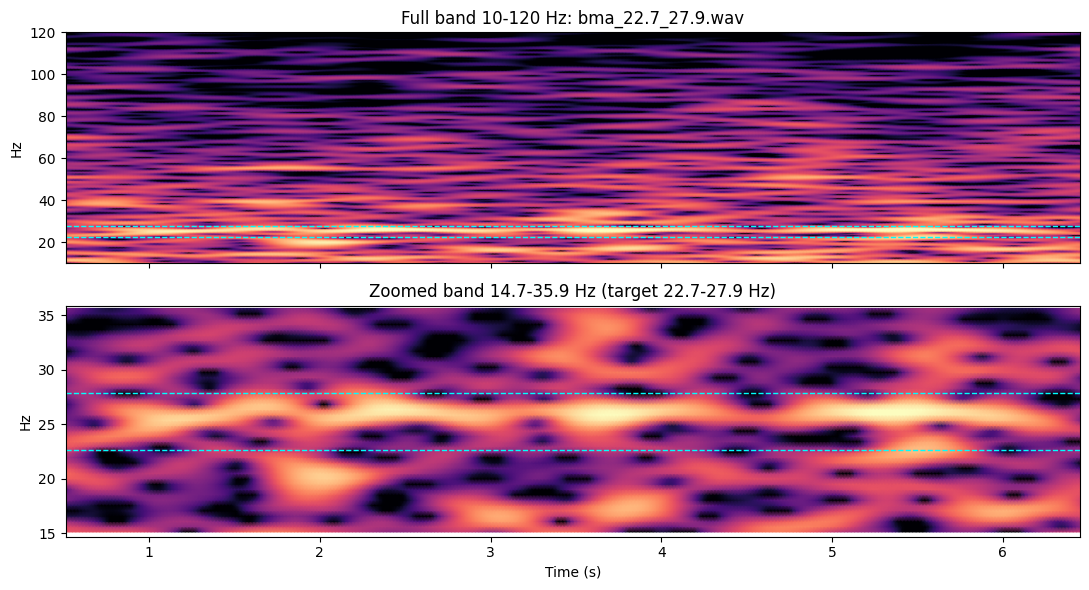

Saved 20 spectrograms to spectrograms_full_band/


In [30]:
import glob
import os
import re
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import spectrogram
import librosa

# Professor settings
N_FFT = 512
WIN_SIZE = 256
OVERLAP_PERCENT = 98
HOP_LENGTH = max(1, int(round(WIN_SIZE * (1 - OVERLAP_PERCENT / 100.0))))  # -> 5

TARGET_SR = 250
FMIN = 10
FMAX = 120


def _extract_target_band_from_filename(file_path):
    """Extract low/high frequency from names like bma_22.7_27.9.wav."""
    name = os.path.basename(file_path)
    m = re.search(r'_(\d+\.\d+)_(\d+\.\d+)\.wav$', name)
    if m:
        return float(m.group(1)), float(m.group(2))
    return None, None


def compute_spectrogram(file_path, show=True, show_zoom=True):
    """
    Build spectrogram with required settings:
    nfft=512 | winsize=256 | overlap=98 | scale=Default (dB)

    Returns
    -------
    S_db : np.ndarray
        10-120 Hz dB spectrogram.
    freqs : np.ndarray
        Frequency axis for S_db.
    times : np.ndarray
        Time axis.
    """
    y, sr = librosa.load(file_path, sr=TARGET_SR, mono=True)

    # PSD spectrogram (smoother rendering than raw STFT magnitude)
    freqs, times, Sxx = spectrogram(
        y,
        fs=sr,
        window='hann',
        nperseg=WIN_SIZE,
        noverlap=WIN_SIZE - HOP_LENGTH,
        nfft=N_FFT,
        mode='psd',
        scaling='density',
    )

    # Convert to dB (default log scale)
    S_db = 10 * np.log10(Sxx + 1e-14)

    # Keep 10-120 Hz
    band = (freqs >= FMIN) & (freqs <= FMAX)
    freqs = freqs[band]
    S_db = S_db[band, :]

    if show:
        low_f, high_f = _extract_target_band_from_filename(file_path)

        if show_zoom and low_f is not None and high_f is not None:
            zmin = max(FMIN, low_f - 8)
            zmax = min(FMAX, high_f + 8)

            fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)

            # Full band panel (10-120 Hz)
            vmin_full = np.percentile(S_db, 10)
            vmax_full = np.percentile(S_db, 99.8)
            axes[0].pcolormesh(
                times,
                freqs,
                S_db,
                shading='gouraud',
                cmap='magma',
                vmin=vmin_full,
                vmax=vmax_full,
            )
            axes[0].axhline(low_f, color='cyan', lw=1, ls='--')
            axes[0].axhline(high_f, color='cyan', lw=1, ls='--')
            axes[0].set_ylim(FMIN, FMAX)
            axes[0].set_ylabel('Hz')
            axes[0].set_title(f'Full band {FMIN}-{FMAX} Hz: {os.path.basename(file_path)}')

            # Zoomed panel around annotated band
            zoom_mask = (freqs >= zmin) & (freqs <= zmax)
            Z = S_db[zoom_mask, :]
            fz = freqs[zoom_mask]
            vmin_zoom = np.percentile(Z, 5)
            vmax_zoom = np.percentile(Z, 99.8)
            axes[1].pcolormesh(
                times,
                fz,
                Z,
                shading='gouraud',
                cmap='magma',
                vmin=vmin_zoom,
                vmax=vmax_zoom,
            )
            axes[1].axhline(low_f, color='cyan', lw=1, ls='--')
            axes[1].axhline(high_f, color='cyan', lw=1, ls='--')
            axes[1].set_ylim(zmin, zmax)
            axes[1].set_ylabel('Hz')
            axes[1].set_xlabel('Time (s)')
            axes[1].set_title(f'Zoomed band {zmin:.1f}-{zmax:.1f} Hz (target {low_f}-{high_f} Hz)')

            plt.tight_layout()
            plt.show()
        else:
            plt.figure(figsize=(10, 4))
            vmin = np.percentile(S_db, 10)
            vmax = np.percentile(S_db, 99.8)
            plt.pcolormesh(times, freqs, S_db, shading='gouraud', cmap='magma', vmin=vmin, vmax=vmax)
            plt.ylim(FMIN, FMAX)
            plt.xlabel('Time (s)')
            plt.ylabel('Hz')
            plt.title(f'Spectrogram {FMIN}-{FMAX} Hz: {os.path.basename(file_path)}')
            plt.colorbar(label='Power (dB)')
            plt.tight_layout()
            plt.show()

    return S_db, freqs, times


def save_all_spectrograms(wav_glob='waves/*.wav', out_dir='spectrograms_full_band'):
    """Save full-band 10-120 Hz spectrogram PNGs for all wave files."""
    os.makedirs(out_dir, exist_ok=True)

    wav_files = sorted(glob.glob(wav_glob))
    for wav_path in wav_files:
        S_db, freqs, times = compute_spectrogram(wav_path, show=False, show_zoom=False)

        plt.figure(figsize=(8, 3))
        vmin = np.percentile(S_db, 10)
        vmax = np.percentile(S_db, 99.8)
        plt.pcolormesh(times, freqs, S_db, shading='gouraud', cmap='magma', vmin=vmin, vmax=vmax)
        plt.ylim(FMIN, FMAX)
        plt.axis('off')

        out_name = os.path.splitext(os.path.basename(wav_path))[0] + '.png'
        out_path = os.path.join(out_dir, out_name)
        plt.savefig(out_path, dpi=150, bbox_inches='tight', pad_inches=0)
        plt.close()

    print(f'Saved {len(wav_files)} spectrograms to {out_dir}/')


# Example: show one file with full band + zoomed target band
compute_spectrogram('waves/bma_22.7_27.9.wav', show=True)

# Example: export all full-band spectrogram images
save_all_spectrograms('waves/*.wav', 'spectrograms_full_band')

